# 02 – Tiền xử lý dữ liệu (TV2)

**Dự án:** Practice 2 – Predicting Product Sales

Notebook này chạy toàn bộ quy trình tiền xử lý từng bước, có in kết quả để đưa vào báo cáo mục 3.
Logic nằm trong `src/tv2_preprocess.py`; notebook chỉ gọi lại các hàm đó nên kết quả luôn khớp với script.

**Thứ tự:** đọc dữ liệu → làm sạch và lọc giao dịch không hợp lệ → gom theo (stockcode × tuần) → chia train/validation/test theo mốc tuần → outlier → imputer/scaler/encoder (chỉ fit trên train) → lưu kết quả → kiểm tra.

> Chạy từ trên xuống dưới bằng *Run All*. Notebook phải nằm trong `notebooks/`, script ở `src/`, dữ liệu gốc ở `data/raw/`.

## 0. Thiết lập

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Gốc dự án: nếu notebook chạy trong thư mục notebooks/ thì lên một cấp.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import tv2_preprocess as pp
print("Đang dùng:", pp.__file__)

# ----- CẤU HÌNH: sửa tên file dữ liệu gốc nếu khác -----
RAW_FILE = ROOT / "data" / "raw" / "dataset.csv"
OUT_DIR = ROOT / "data" / "processed"

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
print("Thư mục dự án:", ROOT)
print("Dữ liệu gốc  :", RAW_FILE, "| tồn tại:", RAW_FILE.exists())
print("Cấu hình     : target =", pp.TARGET, "| date_col =", pp.DATE_COL,
      "| test =", pp.TEST_RATIO, "| validation =", pp.VALIDATION_RATIO,
      "| random_state =", pp.RANDOM_STATE)

Đang dùng: c:\Users\namkh\Downloads\project\project\src\tv2_preprocess.py
Thư mục dự án: c:\Users\namkh\Downloads\project\project
Dữ liệu gốc  : c:\Users\namkh\Downloads\project\project\data\raw\dataset.csv | tồn tại: True
Cấu hình     : target = sales | date_col = invoicedate | test = 0.1 | validation = 0.2 | random_state = 42


## 1. Đọc dữ liệu và chuẩn hóa tên cột

Dữ liệu gốc **không bị chỉnh sửa**; mọi xử lý thực hiện trên bản sao trong bộ nhớ.

**Từ điển cột (sau khi chuẩn hóa về snake_case):**

| Cột | Ý nghĩa |
|---|---|
| `invoice` | Mã hóa đơn; bắt đầu bằng "C" là hóa đơn hủy/hoàn trả |
| `stockcode` | Mã sản phẩm |
| `description` | Tên/mô tả sản phẩm |
| `quantity` | Số lượng trong dòng hóa đơn (âm = hoàn trả/hủy) |
| `invoicedate` | Ngày giờ lập hóa đơn |
| `price` | Đơn giá của một sản phẩm |
| `customer_id` | Mã khách hàng (thiếu khoảng 1/4 số dòng) |
| `country` | Quốc gia của khách hàng |

In [2]:
raw = pp.load_data(RAW_FILE)
df = pp.standardize_columns(raw)
steps = [("Đọc dữ liệu gốc", len(df))]   # nhật ký số dòng theo từng bước
df.head()

,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


In [3]:
info = pp.summarize(df)

Kích thước dữ liệu: (541910, 8)
Số dòng trùng hoàn toàn: 5268
               dtype  n_missing  pct_missing  n_unique
invoice          str          0         0.00     25900
stockcode        str          0         0.00      4070
description      str       1454         0.27      4223
quantity       int64          0         0.00       722
invoicedate      str          0         0.00     23260
price        float64          0         0.00      1630
customer_id  float64     135080        24.93      4372
country          str          0         0.00        38


## 2. Làm sạch

Gắn `row_id` (vị trí dòng trong file gốc) để về sau làm chỉ mục chia, rồi lần lượt xử lý ngày, tạo `sales`, xóa trùng.

In [4]:
df.insert(0, pp.ROW_ID_COL, np.arange(len(df)))

df = pp.parse_dates(df)
df = pp.drop_invalid_dates(df)
steps.append(("Bỏ dòng ngày không hợp lệ", len(df)))

df = pp.create_target(df)           # sales = quantity * price
df = pp.drop_duplicates(df)
steps.append(("Xóa dòng trùng hoàn toàn", len(df)))
df[["invoicedate", "quantity", "price", "sales"]].describe()

Định dạng ngày đã dùng: %m/%d/%y %H:%M
Xóa dòng trùng: 541910 -> 536642 (đã xóa 5268).


,invoicedate,quantity,price,sales
count,536642,536642.000000,536642.000000,536642.000000
mean,2011-07-04 08:57:31.551648,9.620013,4.632681,18.123861
min,2010-12-01 08:26:00,-80995.000000,-11062.060000,-168469.600000
25%,2011-03-28 10:52:00,1.000000,1.250000,3.750000
50%,2011-07-19 14:04:00,3.000000,2.080000,9.870000
75%,2011-10-18 17:05:00,10.000000,4.130000,17.400000
max,2011-12-09 12:50:00,80995.000000,38970.000000,168469.600000
std,NaN,219.129952,97.233029,380.655908


### 2.1 Giao dịch âm / giá bằng 0 / mã không phải sản phẩm

Ô dưới đầu tiên **thống kê** các nhóm dòng bất thường, sau đó **lọc** giao dịch không hợp lệ
(`quantity > 0` và `price > 0`, theo định nghĩa trong báo cáo EDA của TV1).
Việc lọc thêm mã không phải sản phẩm (POST, DOT, M, BANK CHARGES…) do `FILTER_NON_PRODUCT_STOCKCODES`
trong `src/tv2_preprocess.py` quyết định (hiện tắt, nhóm chưa chốt).


In [5]:
pp.report_anomalies(df)

if pp.FILTER_INVALID_TRANSACTIONS:
    df = pp.filter_invalid_transactions(df)
    steps.append(("Lọc giao dịch không hợp lệ (qty>0 & price>0)", len(df)))

if pp.FILTER_NON_PRODUCT_STOCKCODES:
    df = pp.filter_non_product_stockcodes(df)
    steps.append(("Lọc stockcode không phải sản phẩm", len(df)))

df = pp.drop_missing_target(df)
steps.append(("Bỏ dòng thiếu sales", len(df)))


----- THỐNG KÊ DÒNG BẤT THƯỜNG (trước khi lọc) -----
Hóa đơn hủy (invoice bắt đầu bằng 'C'): 9251
Dòng quantity < 0: 10587
Dòng quantity == 0: 0
Dòng price < 0: 2
Dòng price == 0: 2510
Dòng có stockcode không dạng mã sản phẩm: 2990
  Các mã phổ biến nhất: POST (1257), DOT (710), M (566), C2 (144), D (77), S (62), BANK CHARGES (37), AMAZONFEE (34)
------------------------------------------------------

Lọc giao dịch không hợp lệ (quantity>0 & price>0): 536642 -> 524879 (bỏ 11763).
Bỏ dòng thiếu/không hợp lệ ở sales: 524879 -> 524879 (đã bỏ 0).


In [6]:
steps_df = pd.DataFrame(steps, columns=["bước", "số dòng sau bước"])
steps_df["số dòng bị bỏ"] = (steps_df["số dòng sau bước"].shift(1)
                             - steps_df["số dòng sau bước"]).fillna(0).astype(int)
steps_df

,bước,số dòng sau bước,số dòng bị bỏ
0,Đọc dữ liệu gốc,541910,0
1,Bỏ dòng ngày không hợp lệ,541910,0
2,Xóa dòng trùng hoàn toàn,536642,5268
3,Lọc giao dịch không hợp lệ (qty>0 & price>0),524879,11763
4,Bỏ dòng thiếu sales,524879,0


## 3. Gom theo (stockcode × tuần) và chia train / validation / test

- Gom về mức (stockcode × tuần): `sales = Σ(quantity × price)`; chỉ giữ các cặp có phát sinh giao dịch.
- Chia theo **mốc tuần** (tuần bắt đầu từ thứ Hai): tuần cũ nhất là train, tiếp theo là validation, mới nhất là test.
- Mốc ngày trong `SPLIT_CUTOFFS` được đưa về đầu tuần nên **không có tuần nào bị cắt đôi** giữa hai tập.
- Validation dùng chọn mô hình/tuning; **test chỉ dùng đánh giá cuối** (TV6).


In [7]:
weekly = pp.aggregate_weekly(df)                          # mức (stockcode × tuần)
train, validation, test, split_meta = pp.split_weekly(weekly)
split_meta

Tổng hợp (stockcode × tuần): 524879 dòng giao dịch -> 101579 quan sát tuần (3922 sản phẩm, 53 tuần).
Tổng doanh thu sau tổng hợp: 10,642,128.80
Chia theo mốc tuần (quá khứ -> tương lai).
Train: 2010-11-29 -> 2011-09-26
Validation bắt đầu tuần: 2011-10-03 (2011-10-03 -> 2011-11-14)
Test bắt đầu tuần: 2011-11-21 (2011-11-21 -> 2011-12-05)
Train: 78763 (77.5%) | Validation: 15800 (15.6%) | Test: 7016 (6.9%)


{'method': 'time_cutoff_weekly',
 'validation_start_week': '2011-10-03 00:00:00',
 'test_start_week': '2011-11-21 00:00:00',
 'cutoffs_input': ['2011-10-03', '2011-11-21'],
 'n_weeks': {'train': 43, 'validation': 7, 'test': 3}}

In [8]:
# Kiểm tra không rò rỉ thời gian ở mức tuần: tập sau luôn muộn hơn tập trước.
d = pp.WEEK_COL
assert train[d].max() < validation[d].min(), "train lẫn vào validation"
assert validation[d].max() < test[d].min(), "validation lẫn vào test"
assert not (set(train[d]) & set(validation[d])), "trùng tuần train/validation"
assert not (set(validation[d]) & set(test[d])), "trùng tuần validation/test"
print("OK: các tập tách biệt hoàn toàn theo tuần.")

pd.DataFrame({
    "tập": ["train", "validation", "test"],
    "số dòng": [len(train), len(validation), len(test)],
    "số tuần": [x[pp.WEEK_COL].nunique() for x in (train, validation, test)],
    "từ tuần": [x[pp.WEEK_COL].min() for x in (train, validation, test)],
    "đến tuần": [x[pp.WEEK_COL].max() for x in (train, validation, test)],
})

OK: các tập tách biệt hoàn toàn theo tuần.


,tập,số dòng,số tuần,từ tuần,đến tuần
0,train,78763,43,2010-11-29,2011-09-26
1,validation,15800,7,2011-10-03,2011-11-14
2,test,7016,3,2011-11-21,2011-12-05


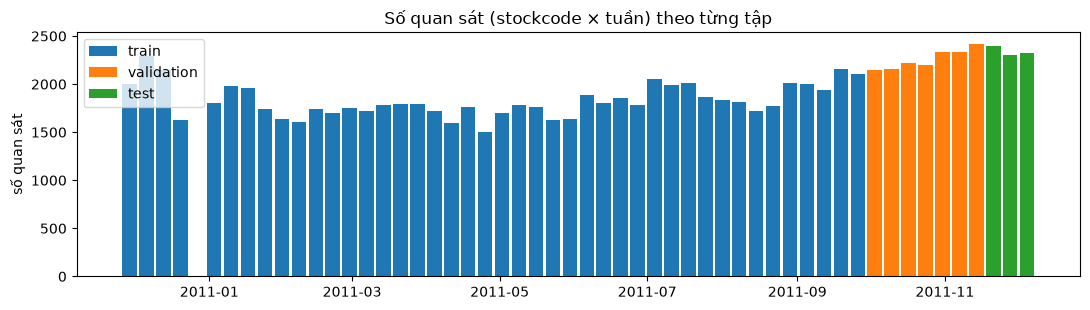

In [9]:
# Minh họa trục thời gian: số quan sát (stockcode × tuần) mỗi tuần, tô màu theo tập.
fig, ax = plt.subplots(figsize=(11, 3.2))
for name, part, color in (("train", train, "tab:blue"),
                          ("validation", validation, "tab:orange"),
                          ("test", test, "tab:green")):
    counts = part.groupby(pp.WEEK_COL).size()
    ax.bar(counts.index, counts.values, width=6.0, color=color, label=name)
ax.set_title("Số quan sát (stockcode × tuần) theo từng tập")
ax.set_ylabel("số quan sát")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Outlier

Chỉ clip các cột trong `OUTLIER_COLS`; ngưỡng IQR tính **chỉ từ train**. Danh sách này đang để trống
vì đơn hàng rất lớn có thể là doanh thu thật (bán buôn) và nhóm chưa chốt sau EDA.
Bảng dưới giúp nhóm xem phân phối của `sales` trên train trước khi quyết định.

In [10]:
print("OUTLIER_COLS hiện tại:", pp.OUTLIER_COLS)
q = train[pp.TARGET].quantile([0, .01, .05, .25, .5, .75, .95, .99, 1])
q.to_frame("sales (train)")

OUTLIER_COLS hiện tại: []


,sales (train)
0.00,0.0010
0.01,0.8300
0.05,2.1000
0.25,9.9000
0.50,26.4400
0.75,79.6000
0.95,356.6980
0.99,988.2144
1.00,77183.6000


In [11]:
outlier_cols = [c for c in pp.OUTLIER_COLS
                if c in train.columns and c != pp.TARGET and c not in pp.ID_COLS]
bounds = pp.fit_iqr_bounds(train, outlier_cols)
train = pp.apply_iqr_bounds(train, bounds)
validation = pp.apply_iqr_bounds(validation, bounds)
test = pp.apply_iqr_bounds(test, bounds)
print("Ngưỡng IQR (fit trên train):", bounds if bounds else "không clip cột nào")

Ngưỡng IQR (fit trên train): không clip cột nào


## 5. Imputer + Scaler + One-hot (chỉ fit trên train)

- Cột ID (`invoice`, `stockcode`, `customer_id`, `description`) **không** đưa vào feature.
- `quantity`, `price` bị loại vì `sales = quantity × price`; `total_qty`, `avg_price`, `order_count` bị loại vì tính từ chính các giao dịch của tuần đang dự đoán (tránh rò rỉ target). TV3 sẽ tạo lag/rolling từ các tuần trước.
- Danh mục mới ở validation/test được bỏ qua an toàn (`handle_unknown="ignore"`).

In [12]:
num_cols, cat_cols = pp.get_feature_types(train)
feature_cols = num_cols + cat_cols
print("Feature số         :", num_cols)
print("Feature phân loại  :", cat_cols)

preprocessor = pp.build_preprocessor(num_cols, cat_cols)
preprocessor.fit(train[feature_cols])            # FIT DUY NHẤT trên train

X_train = pp.transform_features(preprocessor, train, feature_cols)
X_validation = pp.transform_features(preprocessor, validation, feature_cols)
X_test = pp.transform_features(preprocessor, test, feature_cols)
print("Kích thước X:", X_train.shape, X_validation.shape, X_test.shape)
X_train.head()

Feature số         : []
Feature phân loại  : ['country']
Kích thước X: (78763, 37) (15800, 37) (7016, 37)


,cat__country_Australia,cat__country_Austria,cat__country_Bahrain,cat__country_Belgium,cat__country_Brazil,cat__country_Canada,cat__country_Channel Islands,cat__country_Cyprus,cat__country_Czech Republic,cat__country_Denmark,cat__country_EIRE,cat__country_European Community,cat__country_Finland,cat__country_France,cat__country_Germany,cat__country_Greece,cat__country_Hong Kong,cat__country_Iceland,cat__country_Israel,cat__country_Italy,cat__country_Japan,cat__country_Lebanon,cat__country_Lithuania,cat__country_Malta,cat__country_Netherlands,cat__country_Norway,cat__country_Poland,cat__country_Portugal,cat__country_Saudi Arabia,cat__country_Singapore,cat__country_Spain,cat__country_Sweden,cat__country_Switzerland,cat__country_USA,cat__country_United Arab Emirates,cat__country_United Kingdom,cat__country_Unspecified
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [13]:
# Thử một danh mục chưa từng thấy ở train: phải không báo lỗi.
demo = train[feature_cols].head(3).copy()
for c in cat_cols:
    demo[c] = "DANH_MUC_MOI"
out = pp.transform_features(preprocessor, demo, feature_cols)
print("Danh mục mới -> toàn bộ cột one-hot bằng 0:", bool((out.filter(like=cat_cols[0]) == 0).all().all()) if cat_cols else "không có biến phân loại")

Danh mục mới -> toàn bộ cột one-hot bằng 0: True


## 6. Lưu kết quả

Gọi `run_preprocessing()` để ghi toàn bộ file ra `data/processed/` bằng đúng logic của script
(đảm bảo ai chạy `python src/tv2_preprocess.py` cũng nhận được cùng kết quả).

In [14]:
tr2, va2, te2, pre2 = pp.run_preprocessing(RAW_FILE, OUT_DIR)

# Kết quả của script phải khớp với các bước chạy tay ở trên.
assert (len(tr2), len(va2), len(te2)) == (len(train), len(validation), len(test))
print("\nOK: số dòng khớp giữa notebook và script.")


===== KIỂM TRA DỮ LIỆU BAN ĐẦU =====
Kích thước dữ liệu: (541910, 8)
Số dòng trùng hoàn toàn: 5268
               dtype  n_missing  pct_missing  n_unique
invoice          str          0         0.00     25900
stockcode        str          0         0.00      4070
description      str       1454         0.27      4223
quantity       int64          0         0.00       722
invoicedate      str          0         0.00     23260
price        float64          0         0.00      1630
customer_id  float64     135080        24.93      4372
country          str          0         0.00        38
Định dạng ngày đã dùng: %m/%d/%y %H:%M
Xóa dòng trùng: 541910 -> 536642 (đã xóa 5268).

----- THỐNG KÊ DÒNG BẤT THƯỜNG (trước khi lọc) -----
Hóa đơn hủy (invoice bắt đầu bằng 'C'): 9251
Dòng quantity < 0: 10587
Dòng quantity == 0: 0
Dòng price < 0: 2
Dòng price == 0: 2510
Dòng có stockcode không dạng mã sản phẩm: 2990
  Các mã phổ biến nhất: POST (1257), DOT (710), M (566), C2 (144), D (77), S (62), BA

## 7. Kiểm tra file đã lưu

In [15]:
files = sorted(p.name for p in OUT_DIR.iterdir())
print("Các file trong", OUT_DIR, ":")
for f in files:
    print(" -", f)

idx = pd.read_csv(OUT_DIR / "split_index.csv")
print("\nChỉ mục chia:", idx["split"].value_counts().to_dict())
print("Số cặp (stockcode, week_start) duy nhất:",
      not idx.duplicated(["stockcode", pp.WEEK_COL]).any())

for name in ("train", "validation", "test"):
    X = pd.read_csv(OUT_DIR / f"X_{name}.csv")
    y = pd.read_csv(OUT_DIR / f"y_{name}.csv")
    assert len(X) == len(y), f"X và y của {name} lệch số dòng"
    assert not X.isna().any().any(), f"X_{name} còn giá trị thiếu"
print("OK: X và y cùng số dòng, X không còn giá trị thiếu.")

cl = pd.read_csv(OUT_DIR / "cleaned_lines.csv", usecols=[pp.WEEK_COL, "split"])
print("cleaned_lines theo tập:", cl["split"].value_counts().to_dict())
pd.read_csv(OUT_DIR / "preprocessing_steps.csv")

Các file trong c:\Users\namkh\Downloads\project\project\data\processed :
 - X_test.csv
 - X_train.csv
 - X_validation.csv
 - cleaned_lines.csv
 - preprocessing_info.json
 - preprocessing_steps.csv
 - preprocessor.joblib
 - split_index.csv
 - test.csv
 - train.csv
 - validation.csv
 - y_test.csv
 - y_train.csv
 - y_validation.csv

Chỉ mục chia: {'train': 78763, 'validation': 15800, 'test': 7016}
Số cặp (stockcode, week_start) duy nhất: True
OK: X và y cùng số dòng, X không còn giá trị thiếu.
cleaned_lines theo tập: {'train': 360903, 'validation': 109063, 'test': 54913}


,buoc,so_dong_sau_buoc,so_dong_bi_bo
0,Đọc dữ liệu gốc,541910,0
1,Bỏ dòng ngày không hợp lệ,541910,0
2,Xóa dòng trùng hoàn toàn,536642,5268
3,Lọc giao dịch không hợp lệ (qty>0 & price>0),524879,11763
4,Bỏ dòng thiếu sales,524879,0
5,"Tổng hợp (stockcode × tuần) - gom nhóm, không ...",101579,0


## 8. Tóm tắt cho báo cáo mục 3

Điền số liệu thật từ các bảng ở trên:

- **Làm sạch:** bảng số dòng trước/sau từng bước (mục 2); số dòng trùng đã xóa. Dòng "Tổng hợp" là gom nhóm, không phải dòng bị loại.
- **Giá trị thiếu:** `customer_id`, `description` (xem mục 1); cột ID không dùng làm feature nên không cần điền.
- **Giao dịch âm/hoàn trả, giá ≤ 0:** đã lọc theo `quantity > 0` và `price > 0` (khớp TV1); ghi số dòng bị loại và lý do.
- **Mã không phải sản phẩm, outlier của `sales`:** ghi quyết định cuối cùng của nhóm và lý do.
- **Encoding:** `country` dùng one-hot, `handle_unknown="ignore"`; mã định danh không mã hóa.
- **Chia dữ liệu:** chia theo mốc tuần; ghi rõ tuần bắt đầu validation/test, số tuần và tỷ lệ thực tế, lý do (dự đoán tương lai, tránh lẫn thông tin tương lai).
- **Chống rò rỉ:** imputer/scaler/encoder/ngưỡng IQR chỉ fit trên train; loại `quantity`, `price`, `total_qty`, `avg_price`, `order_count` khỏi feature của TV2.

## Hướng dẫn chạy lại

```bash
pip install -r requirements.txt   # pandas, numpy, scikit-learn, joblib, matplotlib
python src/tv2_preprocess.py      # chạy từ thư mục gốc dự án
# hoặc mở notebooks/02_preprocess.ipynb và chọn Run All
```
